# Saturday Lab: Convolutional Neural Networks

## From image pixels to a trained CNN

Today we will learn what convolutional layers do, trace the shapes through a CNN, and train a Rock–Paper–Scissors image classifier. On Sunday, the trained model will be introduced as part of a FastAPI + Streamlit project.

### Learning goals
- Explain local connections and shared filters.
- Calculate output dimensions for convolution and pooling.
- Build a small CNN and inspect its layer shapes and parameter count.
- Train and evaluate the model; inspect mistakes rather than relying only on accuracy.

**Estimated class use:** concept discussion + exercises, then data inspection and a short model-training run. Have the local dataset ready before class.

In [33]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Conv2D , Input, Dense, MaxPooling2D

IMAGE_SIZE = (96, 96)
class_names = ['paper', 'rock', 'scissors']
NUM_CLASSES = len(class_names)

print('TensorFlow:', tf.__version__)
print('Image size:', IMAGE_SIZE)
print('Class order:', class_names)

TensorFlow: 2.18.1
Image size: (96, 96)
Class order: ['paper', 'rock', 'scissors']


In [2]:
print(np.__version__)

2.0.2


## 2. Why use a CNN for images?

An image is a grid of pixel values. Nearby pixels often form useful patterns: edges, corners, textures, and object parts. A dense ANN flattens the image and connects every pixel to every neuron. A CNN instead uses **local connections** and **shared filter weights**. The same filter can detect a pattern at many image positions.

For an image of height $H$, width $W$, and $C$ channels, a dense layer with $U$ units has roughly $HWC 	imes U$ weights. A convolution with a $K 	imes K$ filter and $F$ output filters has roughly $K^2 C F$ weights (plus biases).

### Think-pair-share
Why might the same edge detector be useful near the top, middle, or bottom of an image? What information can flattening make harder to use?

In [3]:
img = plt.imread("images\Fig0219(rose1024).tif")
img

array([[21, 17, 15, ..., 23, 23, 23],
       [20, 19, 17, ..., 23, 23, 23],
       [17, 17, 20, ..., 24, 23, 23],
       ...,
       [ 7,  7,  7, ..., 21, 21, 21],
       [10, 10, 10, ..., 17, 17, 17],
       [10, 10, 10, ..., 15, 15, 15]], dtype=uint8)

In [4]:
img.shape

(1024, 1024)

In [5]:
img

array([[21, 17, 15, ..., 23, 23, 23],
       [20, 19, 17, ..., 23, 23, 23],
       [17, 17, 20, ..., 24, 23, 23],
       ...,
       [ 7,  7,  7, ..., 21, 21, 21],
       [10, 10, 10, ..., 17, 17, 17],
       [10, 10, 10, ..., 15, 15, 15]], dtype=uint8)

In [26]:
filter = np.array(
    [[-4, 0, 4],
    [-4, 0, 4],
    [-4, 0, 4]]
)

In [11]:
np.sum(img[0:3, 0:3] * filter)

np.int64(-6)

In [27]:
nro, nco = img.shape

out_img = np.zeros((nro-2, nco-2))

out_img.shape

(1022, 1022)

In [28]:
for i in range(out_img.shape[0]):
    for j in range(out_img.shape[1]):
        out_img[i, j] = np.sum(img[i:i+3, j:j+3] * filter)

In [24]:
out_img

array([[29.,  7., 27., ..., 43., 17., 23.],
       [ 1., 40., 27., ...,  7., 32., 17.],
       [40.,  3.,  0., ..., -1., 37., 29.],
       ...,
       [-5., -3., -7., ...,  3.,  3.,  3.],
       [ 5.,  5.,  5., ..., 41., 41., 41.],
       [16., 16., 16., ..., 13., 13., 13.]])

(np.float64(-0.5), np.float64(1021.5), np.float64(1021.5), np.float64(-0.5))

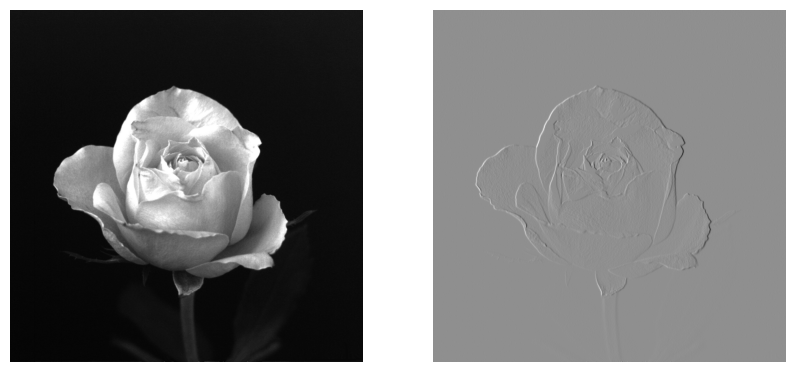

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img, cmap='gray')
ax[0].axis('off')

ax[1].imshow(out_img, cmap='gray')
ax[1].axis('off')

In [30]:
# Compare the number of weights for a dense connection and one convolution layer.
height, width, channels = 96, 96, 3
dense_units = 128
kernel_size, filters = 3, 32
dense_weights = height * width * channels * dense_units
conv_weights = kernel_size * kernel_size * channels * filters
print(f'Dense layer weights: {dense_weights:,}')
print(f'Convolution weights: {conv_weights:,}')

Dense layer weights: 3,538,944
Convolution weights: 864


**Discuss:** this is a comparison of one connection/layer, not two complete equivalent models. The CNN gains its efficiency from local receptive fields and reusing filters across spatial locations.

## 3. Convolution: a filter scans a local patch

At each position, a convolution multiplies filter weights by the matching image values and sums the products. Repeating this operation creates a **feature map**. In a trained CNN, the filter values are learned from examples.

In this small example, a vertical-edge filter responds when values change from dark on the left to bright on the right. It is an illustration of the operation; a trained network learns its own filters.

Patch × filter, summed = 3.0


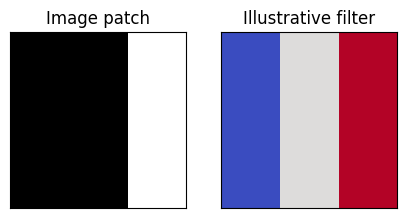

In [ ]:
patch = np.array([[0, 0, 1],
                  [0, 0, 1],
                  [0, 0, 1]], dtype=np.float32)
vertical_edge_filter = np.array([[-1, 0, 1],
                                  [-1, 0, 1],
                                  [-1, 0, 1]], dtype=np.float32)
response = np.sum(patch * vertical_edge_filter)
print('Patch × filter, summed =', response)

fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
axes[0].imshow(patch, cmap='gray', vmin=0, vmax=1); 
axes[0].set_title('Image patch')

axes[1].imshow(vertical_edge_filter, cmap='coolwarm', vmin=-1, vmax=1); 
axes[1].set_title('Illustrative filter')

for ax in axes: ax.set_xticks([]); 
ax.set_yticks([])
plt.show()

### Stride, padding, and output size

- **Stride** is how many pixels the filter moves each step. Larger stride reduces the output resolution.
- **Padding** adds border values so filters can cover image edges and can help preserve spatial size.

For one spatial dimension: $\text{output} = \lfloor (N + 2P - F)/S \rfloor + 1$, where $N$ is input size, $F$ filter size, $P$ padding, and $S$ stride.

In [32]:
def conv_output_size(n, filter_size, padding, stride):
    return (n + 2 * padding - filter_size) // stride + 1

print('Input 7, filter 3, padding 1, stride 1 →', conv_output_size(7, 3, 1, 1))
print('Input 7, filter 3, padding 1, stride 2 →', conv_output_size(7, 3, 1, 2))

Input 7, filter 3, padding 1, stride 1 → 7
Input 7, filter 3, padding 1, stride 2 → 4


**Try it:** for a 32 × 32 input, a 3 × 3 filter, `padding='valid'` (no padding), and stride 1, what is the output height and width? What if stride is 2?

## 4. Activations, pooling, and CNN architecture

A typical classification CNN repeats some combination of **convolution → activation → downsampling**. ReLU adds a nonlinearity. Max pooling keeps the largest response in each small region; strided convolution is another way to downsample. A classifier head turns the final feature maps into class scores.

As layers stack, later units can use information from a larger **receptive field**. CNN history includes early networks such as LeNet, deeper designs such as VGG, and residual networks that use skip connections. These are examples of design ideas, not architectures we need to reproduce today.

In [34]:
# A shape-only pass: follow one RGB image through common CNN layers.
shape_model = tf.keras.Sequential([
    Input(shape=(96, 96, 3)),
    Conv2D(16, 3, padding='same', activation='relu'),
    MaxPooling2D(),
    Conv2D(32, 3, padding='same', activation='relu'),
    MaxPooling2D(),
    tf.keras.layers.GlobalAveragePooling2D(),
    Dense(3, activation='softmax'),
])
shape_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,187 (20.26 KB)

 Trainable params: 5,187 (20.26 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Inspect the Rock–Paper–Scissors data

Place the extracted dataset in `sunday/rps_classifier/datasets/` using the folder structure described in that project's README. The training folder is split into training and validation subsets; the separate test folder is reserved for final evaluation. The model resizes images to 96 × 96 RGB.

Before training, inspect the labels and images. Models can learn background or capture cues as well as the intended gesture, so varied examples and error inspection matter.

In [36]:
DATASET_DIR = Path("datasets")
DATASET_DIR

WindowsPath('datasets')

In [39]:
DATASET_DIR / "rps" / "rps"

WindowsPath('datasets/rps/rps')

In [41]:
BATCH_SIZE = 32
DATASET_DIR = Path('../datasets')
TRAIN_DIR = DATASET_DIR / 'rps' / 'rps'
# TEST_DIR = DATASET_DIR / 'rps-test-set'


# for split_dir in (TRAIN_DIR, TEST_DIR):
#     missing = [name for name in class_names if not (split_dir / name).is_dir()]
#     if missing:
#         raise FileNotFoundError(f'Missing class folders under {split_dir}: {missing}')

# Create a reproducible 15% validation split from the training folders.
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=class_names, validation_split=0.15, subset='training',
    seed=42, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, color_mode='rgb',
    label_mode='int', shuffle=True,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=class_names, validation_split=0.15, subset='validation',
    seed=42, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, color_mode='rgb',
    label_mode='int', shuffle=True,
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

images, labels = next(iter(train_ds))
print('Batch image shape:', images.shape)
print('Batch label shape:', labels.shape)
print('Pixel range before model rescaling:', float(tf.reduce_min(images)), 'to', float(tf.reduce_max(images)))

Found 2520 files belonging to 3 classes.
Using 2142 files for training.
Found 2520 files belonging to 3 classes.
Using 378 files for validation.
Batch image shape: (32, 96, 96, 3)
Batch label shape: (32,)
Pixel range before model rescaling: 7.8984375 to 255.0


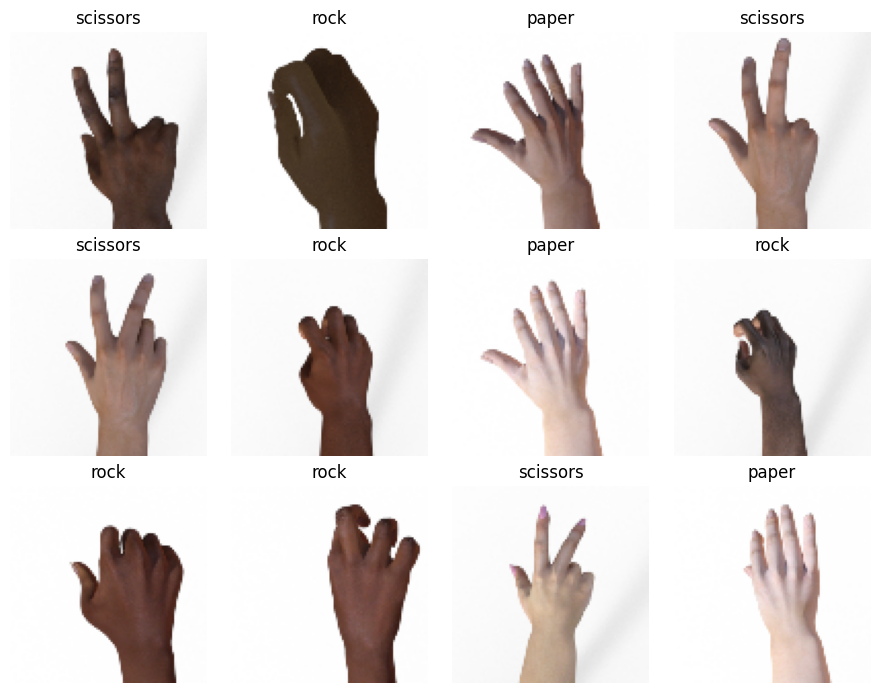

In [42]:
fig, axes = plt.subplots(3, 4, figsize=(9, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(tf.cast(images[i], tf.uint8).numpy())
    ax.set_title(class_names[int(labels[i])])
    ax.axis('off')
plt.tight_layout(); plt.show()

## 6. Build the CNN

We use a small model so it trains in a classroom setting. Its key parts are:
1. Rescaling pixel values to 0–1.
2. Light random augmentation during training.
3. Convolution + batch normalization + ReLU + max pooling blocks.
4. Global average pooling and a three-class softmax output.

Batch normalization and dropout are common tools that can help training and reduce overfitting. They do not guarantee high accuracy; data quality, split design, and image variation still matter.

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.06),
], name='augmentation')

inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='image')
x = tf.keras.layers.Rescaling(1.0 / 255, name='rescale')(inputs)
x = data_augmentation(x)
for filters in (16, 32, 64, 128):
    x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='class_scores')(x)
model = tf.keras.Model(inputs, outputs, name='rps_cnn')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
model.summary()

Model: "rps_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 96, 96, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 96, 96, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 96, 96, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 48, 48, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 98,547 (384.95 KB)

 Trainable params: 98,067 (383.07 KB)

 Non-trainable params: 480 (1.88 KB)

### Before training

The output has three softmax scores, one per class. `sparse_categorical_crossentropy` is appropriate because labels are integer class IDs rather than one-hot vectors. We monitor validation performance to choose a checkpoint; the test split is reserved for the final evaluation.

For a short classroom run, use 3–5 epochs. If the environment is fast and time allows, increase the epoch count.

In [49]:
tf.keras.utils.set_random_seed(42)
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    )],
)

Epoch 1/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 17s 237ms/step - accuracy: 0.9552 - loss: 0.1945 - val_accuracy: 0.3360 - val_loss: 4.4774
Epoch 2/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 16s 241ms/step - accuracy: 0.9603 - loss: 0.1361 - val_accuracy: 0.3360 - val_loss: 4.8413
Epoch 3/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 16s 238ms/step - accuracy: 0.9846 - loss: 0.0722 - val_accuracy: 0.3360 - val_loss: 3.9743
Epoch 4/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 15s 221ms/step - accuracy: 0.9846 - loss: 0.0606 - val_accuracy: 0.4233 - val_loss: 1.3874
Epoch 5/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 14s 201ms/step - accuracy: 0.9933 - loss: 0.0422 - val_accuracy: 0.5291 - val_loss: 1.4480
Epoch 6/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 13s 198ms/step - accuracy: 0.9919 - loss: 0.0385 - val_accuracy: 0.3836 - val_loss: 6.8379
Epoch 7/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 15s 218ms/step - accuracy: 0.9947 - loss: 0.0272 - val_accuracy: 0.6376 - val_loss: 7.5783
Epoch 8/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 19s 282ms/step - accuracy: 0.9908 - loss: 0.0440 - val_accu

In [51]:
history.history

{'accuracy': [0.9584500193595886,
  0.9719887971878052,
  0.9813258647918701,
  0.983660101890564,
  0.9920634627342224,
  0.9939308762550354,
  0.9915966391563416,
  0.985527515411377,
  0.994397759437561],
 'loss': [0.17915061116218567,
  0.11505736410617828,
  0.07395437359809875,
  0.06423159688711166,
  0.0446789376437664,
  0.03771783411502838,
  0.03644774854183197,
  0.05109366029500961,
  0.029406799003481865],
 'val_accuracy': [0.33597883582115173,
  0.33597883582115173,
  0.33597883582115173,
  0.42328041791915894,
  0.5291005373001099,
  0.38359788060188293,
  0.6375661492347717,
  0.6481481194496155,
  0.6349206566810608],
 'val_loss': [4.477358341217041,
  4.841263771057129,
  3.974302053451538,
  1.387425184249878,
  1.447974681854248,
  6.8378520011901855,
  7.5783305168151855,
  4.3633503913879395,
  2.2490835189819336]}

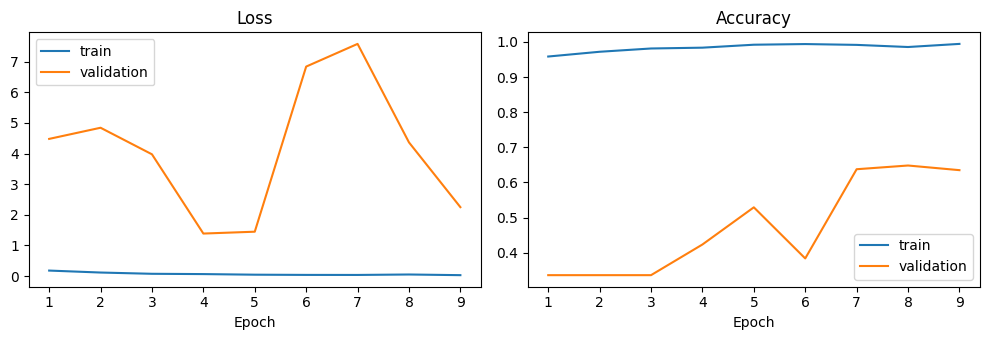

In [53]:
history_values = history.history
epochs_ran = range(1, len(history_values['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(epochs_ran, history_values['loss'], label='train')
axes[0].plot(epochs_ran, history_values['val_loss'], label='validation')
axes[0].set_title('Loss'); 
axes[0].set_xlabel('Epoch'); 
axes[0].legend()

axes[1].plot(epochs_ran, history_values['accuracy'], label='train')
axes[1].plot(epochs_ran, history_values['val_accuracy'], label='validation')
axes[1].set_title('Accuracy'); 
axes[1].set_xlabel('Epoch'); 
axes[1].legend()
plt.tight_layout(); plt.show()

**Discuss the curves:** Is training improving? Is validation improving too? A growing gap between train and validation performance can be a sign of overfitting. Low performance on both can suggest the model has not learned enough, the task/data is difficult, or preprocessing needs review.

## 7. Evaluate and inspect errors

Evaluate on the held-out test split once. A confusion matrix shows which classes the model mixes up. Accuracy alone hides this detail.

Test loss: 1.3874
Test accuracy: 42.3%
Rows = true class; columns = predicted class
[[104  14   0]
 [111  16   0]
 [121  12   0]]


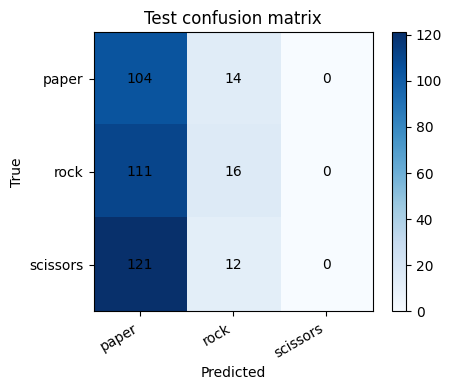

In [54]:
test_loss, test_accuracy = model.evaluate(val_ds, verbose=0)
y_true = np.concatenate([labels.numpy() for _, labels in val_ds])
probabilities = model.predict(val_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
confusion = tf.math.confusion_matrix(y_true, y_pred, num_classes=NUM_CLASSES).numpy()
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.1%}')
print('Rows = true class; columns = predicted class')
print(confusion)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(confusion, cmap='Blues')
ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
       xticklabels=class_names, yticklabels=class_names,
       xlabel='Predicted', ylabel='True', title='Test confusion matrix')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for row in range(NUM_CLASSES):
    for col in range(NUM_CLASSES):
        ax.text(col, row, confusion[row, col], ha='center', va='center')
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

In [ ]:
# Display a few incorrect predictions for discussion.
test_images = np.concatenate([batch.numpy() for batch, _ in test_ds])
wrong = np.flatnonzero(y_true != y_pred)
print(f'Incorrect predictions: {len(wrong)} of {len(y_true)}')
if len(wrong):
    chosen = wrong[:8]
    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    for index, ax in zip(chosen, axes.flat):
        ax.imshow(tf.cast(test_images[index], tf.uint8).numpy())
        ax.set_title(f'True: {class_names[y_true[index]]}\nPred: {class_names[y_pred[index]]}')
        ax.axis('off')
    for ax in axes.flat[len(chosen):]: ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('No errors in this test pass; inspect low-confidence examples as an extension.')

### Error analysis questions
1. Which two gestures are most often confused?
2. Do incorrect images have unusual lighting, framing, backgrounds, or hand positions?
3. Does performance differ across classes? What additional metric would help?
4. What is one data or model change you would test next? Change one thing at a time.

## 8. Save the model for Sunday's app

The FastAPI service expects a Keras model at `models/rps_cnn.keras` and class names at `models/class_names.json`. The model contains its rescaling layer, so API inference should pass RGB pixel values on a 0–255 scale after resizing to 96 × 96.

In [55]:
models_dir = Path('models')
models_dir.mkdir(parents=True, exist_ok=True)
model.save(models_dir / 'rps_cnn.keras')
(models_dir / 'class_names.json').write_text(
    json.dumps(class_names, indent=2), encoding='utf-8'
)
print('Saved model and class names to', models_dir)

Saved model and class names to models


## Wrap-up

A CNN uses shared local filters to form feature maps, then combines those features to predict a class. Today we trained and evaluated one CNN, but the score depends on the dataset and setup; inspecting errors is part of the work.

### Exit ticket
- In your own words, what does one convolution filter produce?
- What changes when stride increases?
- What is one reason the ANN baseline may struggle with image data?
- What preprocessing contract must Sunday's API follow?

### Optional extension
Change one choice (filter count, augmentation, or pooling) and compare validation results. Do not use the test split to choose the change.